# 05 · Agrupamiento de perfiles diarios (tipos de día)

**Entrada:** `data/processed/consumo_horario.parquet` · **Funciones:** `src/features.py` y `src/profiles.py`
**Parámetros:** `src/config.py` (`K_MIN`, `K_MAX`, `TAMANO_MIN_GRUPO`, `SILUETA_RAZONABLE`, `SILUETA_DEBIL`, `MUESTRA_AGRUPAMIENTO`, `SEMILLA`)
**Salida:** `data/processed/tipos_de_dia*.parquet` (días con su grupo, curvas, resumen, mezcla por región y silueta por k), que el notebook 07 exporta para Power BI.

Un **tipo de día** es un grupo de días con la misma *forma* de curva de demanda a lo largo de las 24 horas. No se define por el calendario: el algoritmo descubre los grupos y después se mira en qué fechas cae cada uno.

| Pregunta | Qué responde este notebook | Tarea visual |
|---|---|---|
| P1 | ¿Qué tipos de día existen y cómo se distribuyen en el calendario? | Descubrir patrones |
| P2 | ¿En qué se diferencian las regiones por su mezcla de tipos de día? | Comparar |
| P3 (insumo) | ¿Qué días no encajan en ningún tipo? (distancia al centro del grupo) | Localizar anomalías |

**Diseño del experimento**

| Elemento | Decisión |
|---|---|
| Unidad | Un día operativo (`Datetime − 1 h`) de una región, con sus 24 horas |
| Representación | 24 valores, cada uno dividido entre el promedio del día: se compara la forma y no el nivel (el nivel se guarda aparte en `MW_medio_dia`) |
| Métodos | k-medias y agrupamiento jerárquico (Ward) |
| Número de grupos | k entre `K_MIN` y `K_MAX`, elegido con la silueta media |
| Criterios de cierre | Silueta media reportada (≥ 0.50 estructura razonable; 0.26 a 0.50 débil) y grupos con al menos el 5 % de los días |
| Alcance | Las 12 regiones juntas, para que los tipos de día sean los mismos y se pueda construir la matriz región por tipo de día |

**Contenido**
1. Configuración y carga
2. Perfiles diarios
3. Elección de k
4. Agrupamiento y descripción de los grupos
5. Forma de cada tipo de día
6. Dónde cae cada tipo de día
7. Diferencias entre regiones
8. Días que no encajan en su grupo
9. Guardado
10. Resumen y limitaciones

## 1. Configuración y carga

In [1]:
%load_ext autoreload
%autoreload 2

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.metrics import adjusted_rand_score

from src.config import (
    PROCESSED_DIR, HORAS_POR_DIA, K_MIN, K_MAX, TAMANO_MIN_GRUPO,
    SILUETA_RAZONABLE, SILUETA_DEBIL,
)
from src.features import agregar_variables_temporales
from src.profiles import (
    construir_perfiles, elegir_k, recomendar_k, agrupar, calendario_dias,
    describir_grupos, curvas_grupo, mezcla_por_region, tabla_dias,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DIAS = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

### Parámetros de este notebook

- **`ALINEAR_HORA_CENTRAL`:** en el notebook 03 (sección 6.1), `COMED` llegó una hora más tarde que el resto. Es lo esperable si todas las series están en hora del este y `COMED` está en hora central. Con `False` se conserva la hora de la fuente. Con `True` se resta 1 h a las regiones de `REGIONES_HORA_CENTRAL` antes de calcular el día operativo, de modo que su curva quede alineada con la de las demás. La sección 2.1 mide el desfase de cada región para decidir.
- **`K_ELEGIDO` y `METODO_ELEGIDO`:** con `None` se usa la combinación recomendada por la silueta (sección 3). Para fijar otra, escribe el valor y justifícalo en la sección 3.

In [2]:
ALINEAR_HORA_CENTRAL = False
REGIONES_HORA_CENTRAL = ['COMED', 'NI']   # NI se comprueba en la sección 2.1

K_ELEGIDO = None         # por ejemplo, 4; None = el recomendado por la silueta
METODO_ELEGIDO = None    # 'kmeans' o 'ward'; None = el recomendado

REGION_CALENDARIO = 'PJME'   # región que se dibuja en el calendario (sección 6)

In [3]:
df = pd.read_parquet(PROCESSED_DIR / "consumo_horario.parquet")

if ALINEAR_HORA_CENTRAL:
    centrales = df['region'].isin(REGIONES_HORA_CENTRAL)
    df.loc[centrales, 'Datetime'] -= pd.Timedelta(hours=1)   # hora local central = hora del este − 1 h

df = agregar_variables_temporales(df)   # día operativo: fecha, hora, estación, festivo...
print(f"{len(df):,} filas · {df['region'].nunique()} regiones · alineación a hora central: {ALINEAR_HORA_CENTRAL}")
df.head()

1,090,343 filas · 12 regiones · alineación a hora central: False


,Datetime,MW,region,fecha,anio,mes,hora,dia_semana,es_fin_de_semana,estacion,es_festivo
0,2004-10-01 01:00:00,12379.0,AEP,2004-10-01,2004,10,0,4,False,Otoño,False
1,2004-10-01 02:00:00,11935.0,AEP,2004-10-01,2004,10,1,4,False,Otoño,False
2,2004-10-01 03:00:00,11692.0,AEP,2004-10-01,2004,10,2,4,False,Otoño,False
3,2004-10-01 04:00:00,11597.0,AEP,2004-10-01,2004,10,3,4,False,Otoño,False
4,2004-10-01 05:00:00,11681.0,AEP,2004-10-01,2004,10,4,4,False,Otoño,False


## 2. Perfiles diarios

`construir_perfiles` convierte la serie horaria en una tabla con **una fila por día y región y 24 columnas** (una por hora), y divide cada fila entre el promedio de su día. Un valor de 1.1 significa 10 % por encima del promedio de ese día. Solo se conservan los días con las 24 horas; los extremos incompletos de cada serie se descartan. Los días de cambio de horario conservan sus 24 filas porque la limpieza estimó o promedió la hora afectada.

In [4]:
perfiles, nivel = construir_perfiles(df)

print("Cada perfil suma 24 (promedio 1 por 24 horas):", bool(np.allclose(perfiles.sum(axis=1), HORAS_POR_DIA)))

dias_region = (perfiles.reset_index()
               .groupby('region')['fecha'].agg(desde='min', hasta='max', dias='size'))
dias_region

Días descartados por tener menos de 24 horas: 1
Perfiles: 45,430 días en 12 regiones
Cada perfil suma 24 (promedio 1 por 24 horas): True


,desde,hasta,dias
region,,,
AEP,2004-10-01,2018-08-02,5054
COMED,2011-01-01,2018-08-02,2771
DAYTON,2004-10-01,2018-08-02,5054
DEOK,2012-01-01,2018-08-02,2406
DOM,2005-05-01,2018-08-02,4842
DUQ,2005-01-01,2018-08-02,4962
EKPC,2013-06-01,2018-08-02,1889
FE,2011-06-02,2018-08-02,2619
NI,2004-05-01,2010-12-31,2436


### 2.1 Diagnóstico: ¿está alguna región desplazada en horas?

Para cada región se compara su forma media del día con la del resto, desplazada entre -3 y +3 horas. Un desplazamiento distinto de 0 indica que su curva llega esas horas antes o después. El resto incluye a las otras regiones desplazadas, así que la medida es aproximada, pero basta para detectar `COMED` y comprobar `NI`. Si se activa `ALINEAR_HORA_CENTRAL`, las regiones alineadas deberían pasar a 0.

In [5]:
medio = perfiles.groupby('region').mean()   # forma media de cada región (24 columnas)

filas = []
for r in medio.index:
    ref = medio.drop(index=r).mean().to_numpy()
    errores = {k: np.abs(medio.loc[r].to_numpy() - np.roll(ref, k)).mean() for k in range(-3, 4)}
    filas.append({
        'region': r,
        'hora_pico': int(medio.loc[r].idxmax()),
        'desplazamiento_h': min(errores, key=errores.get),
    })

pd.DataFrame(filas).set_index('region')

,hora_pico,desplazamiento_h
region,,
AEP,18,0
COMED,18,1
DAYTON,18,0
DEOK,18,0
DOM,18,0
DUQ,17,0
EKPC,19,0
FE,18,0
NI,18,1


**Cómo decidir.** Si `COMED` (y `NI`, si también sale con +1) quedan desplazadas, el algoritmo puede separar días por la hora y no por la forma, y la mezcla de tipos de día de esas regiones no sería comparable con la de las demás. En ese caso, poner `ALINEAR_HORA_CENTRAL = True`, volver a ejecutar desde la sección 1 y registrar la decisión en la documentación. Si el desplazamiento es 0 para todas, no hay nada que alinear.

**Decisión:** `[completar]`

## 3. Elección de k

`elegir_k` prueba k-medias y Ward con k entre `K_MIN` y `K_MAX` y calcula la **silueta media** de cada combinación (de -1 a 1; más alto significa grupos más separados). Trabaja sobre una muestra aleatoria reproducible de días, porque la silueta y Ward escalan de forma cuadrática. También devuelve el tamaño del grupo más pequeño, para aplicar el criterio de que cada grupo tenga al menos el 5 % de los días.

Umbrales del proyecto (Kaufman y Rousseeuw): silueta ≥ 0.50, estructura razonable; entre 0.26 y 0.50, estructura débil; por debajo, sin estructura sustancial.

In [6]:
tabla_k = elegir_k(perfiles)

print("Silueta media")
display(tabla_k.pivot(index='k', columns='metodo', values='silueta').round(3))
print("Tamaño del grupo más pequeño (% de los días)")
display(tabla_k.pivot(index='k', columns='metodo', values='min_tamano').mul(100).round(1))

Silueta media


metodo,kmeans,ward
k,,
2,0.413,0.373
3,0.301,0.238
4,0.240,0.189
5,0.245,0.174
6,0.226,0.164
7,0.220,0.159
8,0.205,0.152
9,0.198,0.141
10,0.194,0.132


Tamaño del grupo más pequeño (% de los días)


metodo,kmeans,ward
k,,
2,38.2,46.3
3,26.8,22.7
4,17.6,15.9
5,16.7,12.6
6,6.4,6.0
7,8.0,4.0
8,5.7,4.0
9,5.0,4.0
10,5.7,4.0


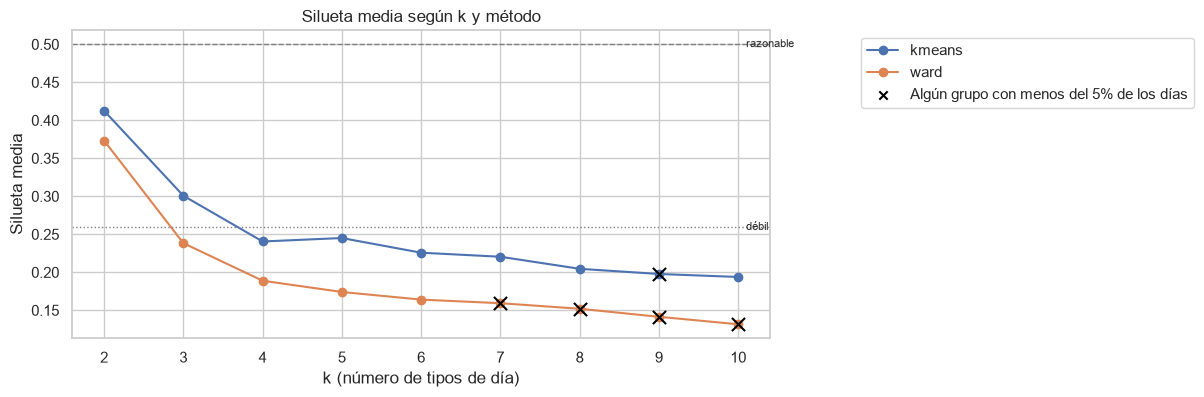

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for metodo, g in tabla_k.groupby('metodo'):
    ax.plot(g['k'], g['silueta'], marker='o', label=metodo)
    sin = g[~g['cumple_tamano']]
    ax.scatter(sin['k'], sin['silueta'], marker='x', s=90, color='black', zorder=3)

ax.scatter([], [], marker='x', color='black', label=f'Algún grupo con menos del {TAMANO_MIN_GRUPO:.0%} de los días')
ax.axhline(SILUETA_RAZONABLE, color='gray', linestyle='--', linewidth=1)
ax.axhline(SILUETA_DEBIL, color='gray', linestyle=':', linewidth=1)
ax.text(K_MAX + 0.1, SILUETA_RAZONABLE, 'razonable', va='center', fontsize=8)
ax.text(K_MAX + 0.1, SILUETA_DEBIL, 'débil', va='center', fontsize=8)
ax.set_xticks(range(K_MIN, K_MAX + 1))
ax.set_xlabel('k (número de tipos de día)')
ax.set_ylabel('Silueta media')
ax.set_title('Silueta media según k y método')
ax.legend(bbox_to_anchor=(1.12, 1), loc='upper left')
plt.show()

In [8]:
mejor = recomendar_k(tabla_k)
print(f"Mayor silueta con grupos de al menos {TAMANO_MIN_GRUPO:.0%}: {mejor['metodo']}, "
      f"k = {int(mejor['k'])}, silueta = {mejor['silueta']:.3f} ({mejor['interpretacion']})")

K = int(K_ELEGIDO) if K_ELEGIDO else int(mejor['k'])
METODO = METODO_ELEGIDO or mejor['metodo']
fila = tabla_k[(tabla_k['k'] == K) & (tabla_k['metodo'] == METODO)].iloc[0]
SILUETA = float(fila['silueta'])
print(f"Se usa: {METODO}, k = {K}, silueta = {SILUETA:.3f}, grupo más pequeño = {fila['min_tamano']:.1%}")
if K > 8:
    print("Aviso: con más de 8 grupos los colores categóricos dejan de distinguirse bien.")

# Alternativas con más detalle (k >= 4)
tabla_k[tabla_k['cumple_tamano'] & (tabla_k['k'] >= 4)].nlargest(3, 'silueta').round(3)

Mayor silueta con grupos de al menos 5%: kmeans, k = 2, silueta = 0.413 (estructura débil)
Se usa: kmeans, k = 2, silueta = 0.413, grupo más pequeño = 38.2%


,metodo,k,silueta,min_tamano,cumple_tamano
3,kmeans,5,0.245,0.166,True
2,kmeans,4,0.240,0.176,True
4,kmeans,6,0.226,0.064,True


**Decisión de k.** Con frecuencia k = 2 gana en silueta, porque dividir en dos es lo más fácil (por ejemplo, laborable frente a fin de semana). Si ocurre, no basta con quedarse con ese número: la tabla de arriba permite justificar un k mayor si sus grupos son más útiles e interpretables, aunque la silueta baje algo. Para fijarlo, usar `K_ELEGIDO` en la sección 1.

**Justificación:** `[completar]`

## 4. Agrupamiento y descripción de los grupos

`agrupar` asigna **todos** los días a un grupo (el 1 es el más frecuente). Si el método es Ward, se ajusta sobre una muestra y el resto de días se asigna al centro más cercano. Para saber si el resultado depende del método, se calcula el **índice de Rand ajustado** entre k-medias y Ward con el mismo k (1 = grupos idénticos; cerca de 0 = sin relación).

In [9]:
etiquetas = agrupar(perfiles, K, METODO)

otro = 'ward' if METODO == 'kmeans' else 'kmeans'
ari = adjusted_rand_score(etiquetas, agrupar(perfiles, K, otro))
print(f"Concordancia con {otro} (índice de Rand ajustado): {ari:.2f}")

Concordancia con ward (índice de Rand ajustado): 0.82


In [10]:
calendario = calendario_dias(df)
resumen = describir_grupos(perfiles, etiquetas, calendario).rename_axis('grupo')

print(f"Los porcentajes suman {resumen['pct_dias'].sum():.1f} %")
print("Todos los grupos tienen al menos el 5 % de los días:", bool(resumen['cumple_tamano'].all()))
resumen.round(1)

Los porcentajes suman 100.0 %
Todos los grupos tienen al menos el 5 % de los días: True


,n_dias,pct_dias,hora_pico,hora_minimo,amplitud,pct_fin_de_semana,pct_festivo,estacion_dominante,pct_estacion_dominante,cumple_tamano
grupo,,,,,,,,,,
1,28299,62.3,19,3,0.2,28.9,3.2,Invierno,38.1,True
2,17131,37.7,17,4,0.4,28.1,2.8,Verano,63.0,True


**Cómo leer la tabla.** `hora_pico` y `hora_minimo` son horas de inicio (0 = 00:00–01:00). `amplitud` es la diferencia entre el máximo y el mínimo de la curva, en fracción del promedio del día. `pct_fin_de_semana` es el porcentaje de días del grupo que son sábado o domingo (si los fines de semana fueran independientes del grupo, sería cercano a 28.6 %). `estacion_dominante` y `pct_estacion_dominante` indican en qué estación cae la mayoría de los días del grupo.

In [11]:
def nombre_sugerido(g, fila):
    """Nombre provisional a partir del calendario del grupo (revisar a mano)."""
    if fila['pct_fin_de_semana'] >= 60:
        dia = 'fin de semana'
    elif fila['pct_fin_de_semana'] <= 10:
        dia = 'laborable'
    else:
        dia = 'mixto'
    return f"G{g} · {fila['estacion_dominante']} · {dia}"

NOMBRES = {g: nombre_sugerido(g, fila) for g, fila in resumen.iterrows()}

# Para fijar nombres a mano tras revisar las curvas, reemplazar por algo como:
# NOMBRES = {1: 'Laborable de verano', 2: 'Laborable de invierno', ...}
pd.Series(NOMBRES, name='nombre_sugerido').to_frame()

,nombre_sugerido
1,G1 · Invierno · mixto
2,G2 · Verano · mixto


## 5. Forma de cada tipo de día

Curva media de cada grupo con una banda entre los percentiles 10 y 90. Todos los paneles comparten la misma escala, así que las formas se comparan por posición sobre un eje común. La línea gris marca el promedio del día (1.0).

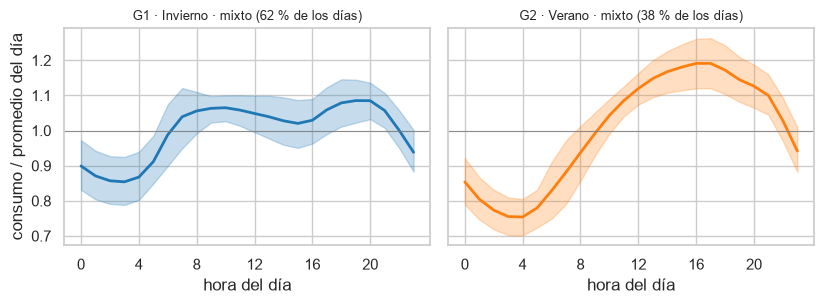

In [12]:
curvas = curvas_grupo(perfiles, etiquetas)
colores = sns.color_palette('tab10', K)
grupos = sorted(curvas['grupo'].unique())

ncols = min(4, K)
nrows = math.ceil(K / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows),
                         sharex=True, sharey=True, squeeze=False)

for ax, g in zip(axes.flat, grupos):
    c = curvas[curvas['grupo'] == g]
    ax.fill_between(c['hora'], c['inferior'], c['superior'], color=colores[g - 1], alpha=0.25)
    ax.plot(c['hora'], c['media'], color=colores[g - 1], linewidth=2)
    ax.axhline(1, color='gray', linewidth=0.6)
    ax.set_title(f"{NOMBRES[g]} ({resumen.loc[g, 'pct_dias']:.0f} % de los días)", fontsize=9)
    ax.set_xticks(range(0, 24, 4))
for ax in axes.flat[len(grupos):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel('hora del día')
for ax in axes[:, 0]:
    ax.set_ylabel('consumo / promedio del día')
plt.tight_layout()
plt.show()

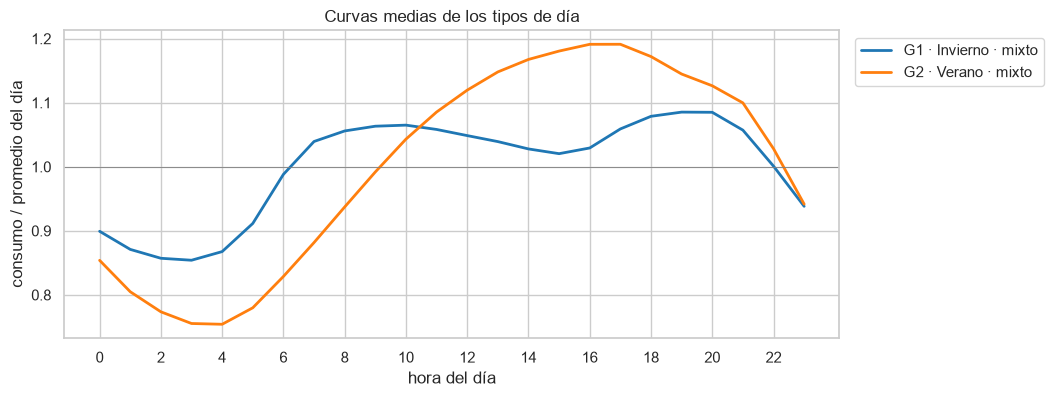

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
for g in grupos:
    c = curvas[curvas['grupo'] == g]
    ax.plot(c['hora'], c['media'], color=colores[g - 1], linewidth=2, label=NOMBRES[g])
ax.axhline(1, color='gray', linewidth=0.6)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('hora del día')
ax.set_ylabel('consumo / promedio del día')
ax.set_title('Curvas medias de los tipos de día')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

**Interpretación.** `[completar]` (qué diferencia a las curvas: hora y altura del pico de la tarde, presencia de un pico hacia las 8 h, amplitud).

## 6. Dónde cae cada tipo de día

### 6.1 Composición de cada grupo por día de la semana y por mes

Porcentaje de los días de cada grupo que cae en cada día de la semana y en cada mes. Si un grupo se concentra en sábados y domingos, o en una estación, el algoritmo capturó el calendario sin que se le diera.

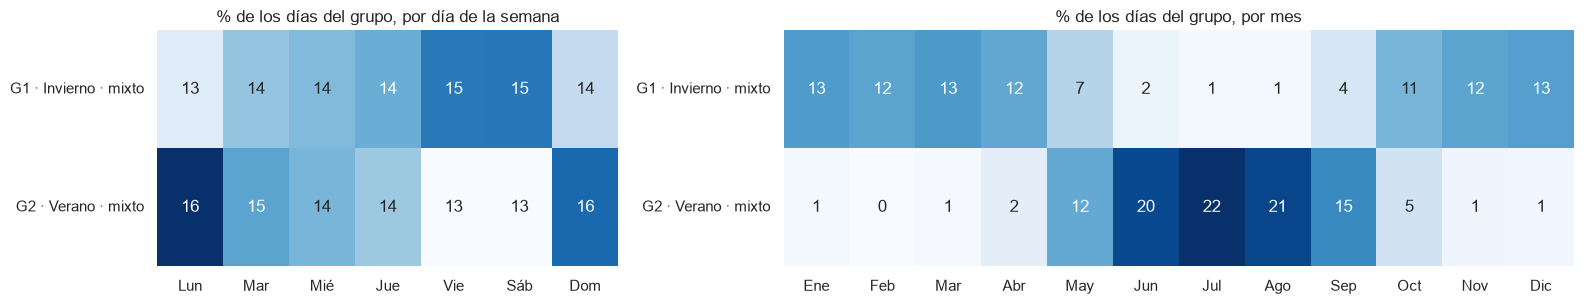

In [14]:
cal = calendario.reindex(perfiles.index)

por_dia = pd.crosstab(etiquetas, cal['dia_semana'], normalize='index').mul(100)
por_dia.columns = DIAS
por_mes = pd.crosstab(etiquetas, cal['mes'], normalize='index').mul(100)
por_mes.columns = MESES
for tabla in (por_dia, por_mes):
    tabla.index = [NOMBRES[g] for g in tabla.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 0.6 * K + 2), gridspec_kw={'width_ratios': [7, 12]})
sns.heatmap(por_dia, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('% de los días del grupo, por día de la semana')
sns.heatmap(por_mes, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=axes[1])
axes[1].set_title('% de los días del grupo, por mes')
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

### 6.2 Calendario de una región

Cada fila es un año y cada columna un día del año; el color indica el tipo de día. Permite ver la ubicación de cada grupo en el calendario (estaciones, fines de semana, festivos) y si cambia con los años. Los espacios en blanco son días sin datos completos.

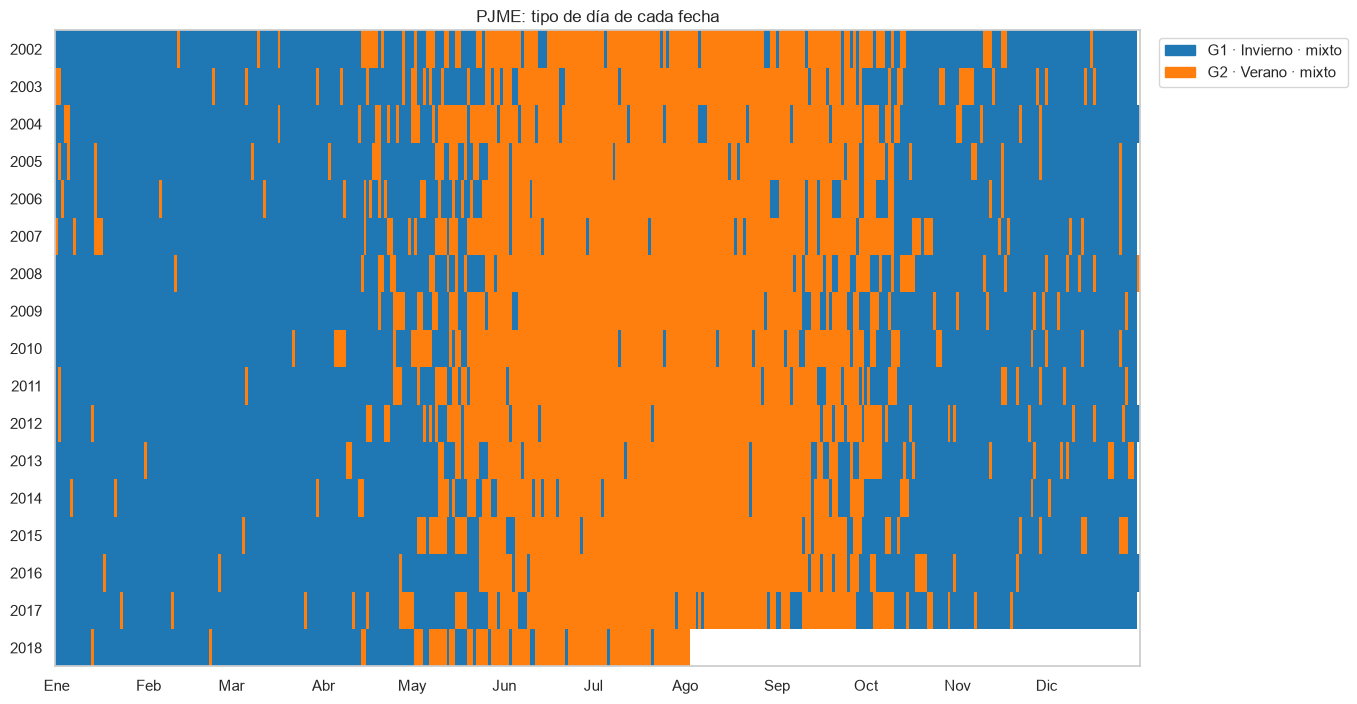

In [15]:
dias = etiquetas.xs(REGION_CALENDARIO, level='region').rename('grupo').reset_index()
dias['anio'] = dias['fecha'].dt.year
dias['doy'] = dias['fecha'].dt.dayofyear
m = dias.pivot(index='anio', columns='doy', values='grupo').reindex(columns=range(1, 367))

fig, ax = plt.subplots(figsize=(14, 0.38 * len(m) + 1.8))
ax.imshow(np.ma.masked_invalid(m.to_numpy(dtype=float)), aspect='auto', interpolation='nearest',
          cmap=ListedColormap(colores), vmin=0.5, vmax=K + 0.5)

inicios_mes = [pd.Timestamp(2021, mes, 1).dayofyear - 1 for mes in range(1, 13)]
ax.set_xticks(inicios_mes)
ax.set_xticklabels(MESES)
ax.set_yticks(range(len(m)))
ax.set_yticklabels(m.index)
ax.grid(False)
ax.set_title(f'{REGION_CALENDARIO}: tipo de día de cada fecha')
ax.legend(handles=[Patch(color=colores[g - 1], label=NOMBRES[g]) for g in grupos],
          bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

**Interpretación.** `[completar]` (qué grupos corresponden a laborables y a fines de semana, cuáles a verano e invierno, dónde caen los festivos, y si algún grupo se concentra en pocos años).

## 7. Diferencias entre regiones

### 7.1 Mezcla de tipos de día por región

Porcentaje de los días de cada región que pertenece a cada tipo. Las barras comparten una línea base común (0 a 100 %). Se ordenan por la proporción del grupo 1.

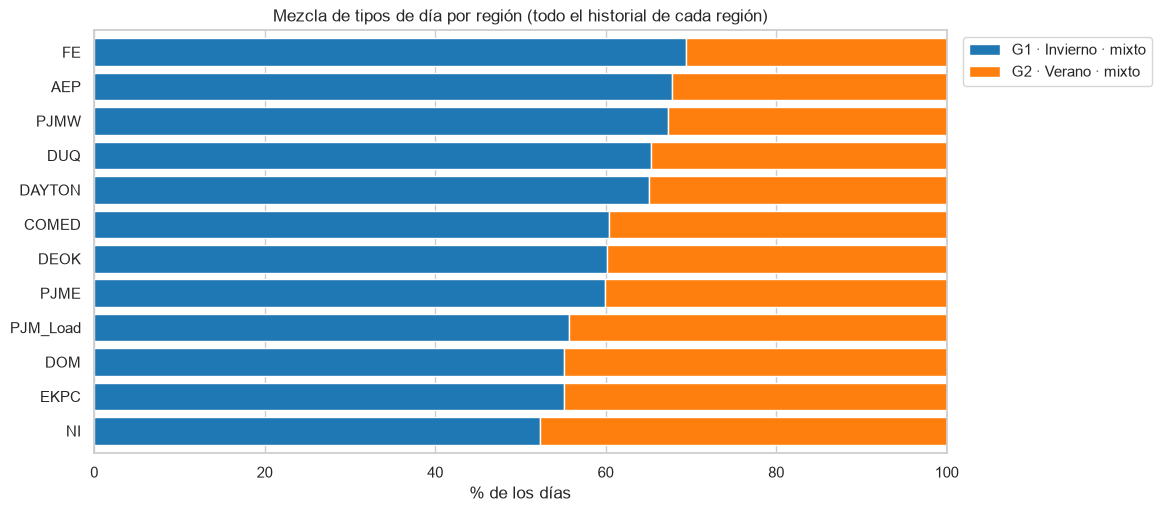

grupo,1,2
region,,
AEP,67.8,32.2
COMED,60.4,39.6
DAYTON,65.1,34.9
DEOK,60.2,39.8
DOM,55.2,44.8
DUQ,65.4,34.6
EKPC,55.2,44.8
FE,69.4,30.6
NI,52.3,47.7


In [16]:
mezcla = mezcla_por_region(etiquetas)

orden = mezcla.sort_values(grupos[0]).index
ax = (mezcla.loc[orden].rename(columns=NOMBRES)
      .plot.barh(stacked=True, color=colores, figsize=(11, 5.5), width=0.8))
ax.set_xlim(0, 100)
ax.set_xlabel('% de los días')
ax.set_ylabel('')
ax.set_title('Mezcla de tipos de día por región (todo el historial de cada región)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

mezcla.round(1)

### 7.2 Mezcla en el periodo común

Las regiones cubren periodos distintos (`PJM_Load` 1998–2002, `NI` 2004–2011, las otras 10 hasta 2018), y el clima de cada periodo cambia la mezcla. Para comparar de forma justa se repite el gráfico solo con las regiones vigentes y su periodo común.

Regiones vigentes (10): ['AEP', 'COMED', 'DAYTON', 'DEOK', 'DOM', 'DUQ', 'EKPC', 'FE', 'PJME', 'PJMW']
Periodo común (días operativos): 2013-06-01 → 2018-08-02


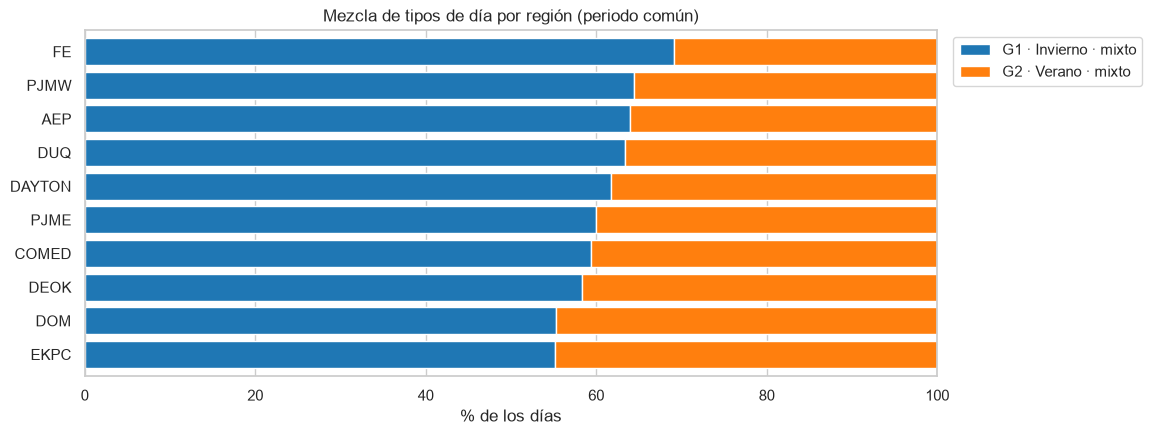

grupo,1,2
region,,
AEP,64.0,36.0
COMED,59.3,40.7
DAYTON,61.8,38.2
DEOK,58.3,41.7
DOM,55.3,44.7
DUQ,63.3,36.7
EKPC,55.2,44.8
FE,69.1,30.9
PJME,60.0,40.0


In [17]:
rango = df.groupby('region')['fecha'].agg(['min', 'max'])
vigentes = rango[rango['max'] >= rango['max'].max() - pd.Timedelta(days=7)]
inicio_comun, fin_comun = vigentes['min'].max(), vigentes['max'].min()
print(f"Regiones vigentes ({len(vigentes)}): {list(vigentes.index)}")
print(f"Periodo común (días operativos): {inicio_comun:%Y-%m-%d} → {fin_comun:%Y-%m-%d}")

fechas = etiquetas.index.get_level_values('fecha')
regs = etiquetas.index.get_level_values('region')
en_comun = regs.isin(vigentes.index) & (fechas >= inicio_comun) & (fechas <= fin_comun)

mezcla_comun = mezcla_por_region(etiquetas[en_comun])

orden = mezcla_comun.sort_values(grupos[0]).index
ax = (mezcla_comun.loc[orden].rename(columns=NOMBRES)
      .plot.barh(stacked=True, color=colores, figsize=(11, 4.5), width=0.8))
ax.set_xlim(0, 100)
ax.set_xlabel('% de los días')
ax.set_ylabel('')
ax.set_title('Mezcla de tipos de día por región (periodo común)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

mezcla_comun.round(1)

### 7.3 Estacionalidad frente a variabilidad dentro del día

Cada punto es una región del periodo común. El eje horizontal es el consumo medio de invierno entre el de verano (mayor que 1: región invernal) y el vertical es la amplitud media de su curva diaria (máximo menos mínimo, en fracción del promedio del día).

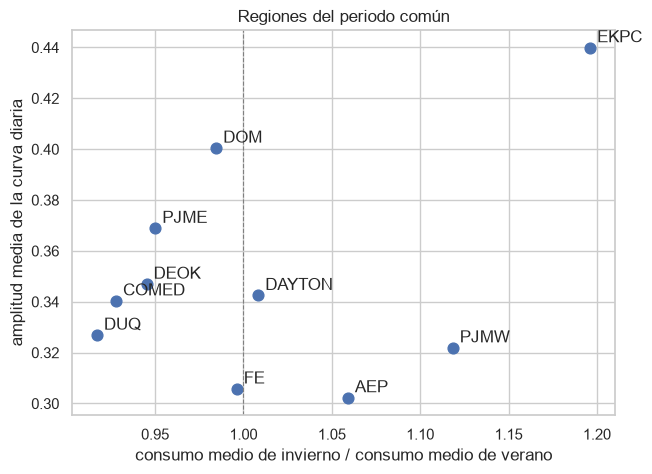

,invierno_verano,amplitud_diaria
region,,
AEP,1.059,0.302
COMED,0.928,0.340
DAYTON,1.008,0.342
DEOK,0.945,0.347
DOM,0.985,0.400
DUQ,0.917,0.327
EKPC,1.196,0.440
FE,0.996,0.306
PJME,0.950,0.369


In [18]:
df_c = df[df['region'].isin(vigentes.index) & df['fecha'].between(inicio_comun, fin_comun)]
est = df_c.groupby(['region', 'estacion'])['MW'].mean().unstack()

perfiles_c = perfiles[en_comun]
disp = pd.DataFrame({
    'invierno_verano': est['Invierno'] / est['Verano'],
    'amplitud_diaria': (perfiles_c.max(axis=1) - perfiles_c.min(axis=1)).groupby('region').mean(),
})

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(disp['invierno_verano'], disp['amplitud_diaria'], s=60)
for r, fila in disp.iterrows():
    ax.annotate(r, (fila['invierno_verano'], fila['amplitud_diaria']),
                xytext=(5, 4), textcoords='offset points')
ax.axvline(1, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('consumo medio de invierno / consumo medio de verano')
ax.set_ylabel('amplitud media de la curva diaria')
ax.set_title('Regiones del periodo común')
plt.show()

disp.round(3)

**Interpretación.** `[completar]` (qué regiones tienen más días de cada tipo, cuáles se parecen entre sí, y cómo se relaciona la mezcla con el sesgo invernal o veraniego del notebook 03).

## 8. Días que no encajan en su grupo

La distancia de un día al centro de su grupo (raíz de la suma de los cuadrados de las diferencias en las 24 horas, en unidades del perfil normalizado) mide cuánto se aleja su forma de la de su tipo. Un día muy lejano es un candidato a atípico por forma. Esta lista es un **insumo** para la detección de anomalías del notebook 06, que se basa en los residuos del pronóstico y no en la forma.

In [19]:
centroides = perfiles.groupby(etiquetas).mean()
diferencia = perfiles.to_numpy() - centroides.loc[etiquetas].to_numpy()
distancia = pd.Series(np.sqrt((diferencia ** 2).sum(axis=1)), index=perfiles.index, name='distancia_centroide')

print("Distribución de la distancia por grupo")
display(distancia.groupby(etiquetas).describe(percentiles=[0.5, 0.95, 0.99]).round(3))

print("Los 10 días más alejados de su grupo")
(distancia.nlargest(10).to_frame().join(etiquetas)
 .join(cal[['dia_semana', 'es_festivo', 'estacion']]).round(3))

Distribución de la distancia por grupo


,count,mean,std,min,50%,95%,99%,max
grupo,,,,,,,,
1,28299.0,0.226,0.103,0.044,0.210,0.397,0.609,1.539
2,17131.0,0.223,0.088,0.035,0.215,0.382,0.485,0.813


Los 10 días más alejados de su grupo


distancia_centroide  grupo  dia_semana  es_festivo  \
region fecha                                                            
DAYTON 2008-09-14                1.539      1           6       False   
EKPC   2017-02-10                1.148      1           4       False   
DAYTON 2012-06-29                1.113      1           4       False   
EKPC   2014-03-07                1.090      1           4       False   
       2018-01-07                1.080      1           6       False   
       2018-02-09                1.045      1           4       False   
       2014-11-19                1.038      1           2       False   
       2017-03-16                1.036      1           3       False   
DOM    2015-03-07                1.028      1           5       False   
EKPC   2014-02-28                1.016      1           4       False   

                    estacion  
region fecha                  
DAYTON 2008-09-14      Otoño  
EKPC   2017-02-10   Invierno  
DAYTON 2012-06-29     Verano  
EKPC   2014-03-07  Primavera  
       2018-01-07   Invierno  
       2018-02-09   Invierno  
       2014-11-19      Otoño  
       2017-03-16  Primavera  
DOM    2015-03-07  Primavera  
EKPC   2014-02-28   Invierno

## 9. Guardado

Tablas intermedias en `data/processed/` (el notebook 07 las convierte al formato final para Power BI):

| Archivo | Contenido |
|---|---|
| `tipos_de_dia.parquet` | Una fila por día y región: grupo, nombre, nivel (`MW_medio_dia`), distancia al centro y variables de calendario |
| `tipos_de_dia_curvas.parquet` | Curva media y banda por grupo y hora |
| `tipos_de_dia_resumen.parquet` | Descripción de cada grupo |
| `tipos_de_dia_mezcla_region.parquet` | Porcentaje de días de cada grupo por región (formato largo) |
| `tipos_de_dia_silueta_k.parquet` | Silueta y tamaño mínimo por método y k |

In [20]:
tipos = (tabla_dias(perfiles, etiquetas, nivel)
         .merge(distancia.reset_index(), on=['region', 'fecha'])
         .merge(calendario.reset_index(), on=['region', 'fecha']))
tipos['nombre_grupo'] = tipos['grupo'].map(NOMBRES)

curvas_g = curvas.assign(nombre_grupo=curvas['grupo'].map(NOMBRES))
resumen_g = resumen.reset_index().assign(nombre_grupo=lambda d: d['grupo'].map(NOMBRES))
mezcla_g = (mezcla.stack().rename('pct_dias').reset_index()
            .assign(nombre_grupo=lambda d: d['grupo'].map(NOMBRES)))

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
archivos = {
    'tipos_de_dia.parquet': tipos,
    'tipos_de_dia_curvas.parquet': curvas_g,
    'tipos_de_dia_resumen.parquet': resumen_g,
    'tipos_de_dia_mezcla_region.parquet': mezcla_g,
    'tipos_de_dia_silueta_k.parquet': tabla_k,
}
for nombre, tabla in archivos.items():
    tabla.to_parquet(PROCESSED_DIR / nombre, index=False)
    print(f"{nombre}: {len(tabla):,} filas")

tipos_de_dia.parquet: 45,430 filas
tipos_de_dia_curvas.parquet: 48 filas
tipos_de_dia_resumen.parquet: 2 filas
tipos_de_dia_mezcla_region.parquet: 24 filas
tipos_de_dia_silueta_k.parquet: 18 filas


## 10. Resumen y limitaciones


### Diseño aplicado

| Elemento | Valor |
|---|---|
| Días agrupados |  días de 12 regiones |
| Representación | 24 valores por día, divididos entre el promedio del día |
| Alineación de `COMED` y `NI` a hora central |  |
| Método elegido |  |
| k elegido |  |

### Resultados

| Indicador | Valor |
|---|---|
| Silueta media (muestra) |  |
| Interpretación |  (≥ 0.50 razonable; 0.26 a 0.50 débil) |
| Grupo más pequeño |  % de los días |
| Concordancia entre k-medias y Ward (Rand ajustado) |  |

### Tipos de día

| Grupo | Nombre | % de los días | Hora pico | Calendario dominante |
|---|---|---|---|---|
|  |  |  |  |  |

**Interpretación:** 


### Limitaciones

- **Estructura posiblemente débil.** Los perfiles diarios forman en parte un continuo, así que los tipos de día son una simplificación útil y no categorías naturalmente separadas. Hay que reportar la silueta tal como sale.
- **Sin temperatura.** Es el principal determinante de la demanda y el dataset no la incluye; los tipos de día se interpretan por el calendario y no por el clima.
- **Se pierde el nivel.** Al dividir entre el promedio del día se compara solo la forma. El nivel se conserva en `MW_medio_dia`, pero no interviene en el agrupamiento.
- **Agrupamiento conjunto.** Las 12 regiones comparten los tipos de día, lo que permite compararlas, pero puede esconder formas propias de una región.
- **Periodos desiguales.** La mezcla de cada región depende también de los años que cubre; por eso se compara además en el periodo común.
- **Hora de `COMED` y `NI`.** Si no se alinean a hora central, su curva llega una hora más tarde y la comparación de formas con otras regiones se distorsiona.
- **Muestra para elegir k.** La silueta y Ward se calculan sobre una muestra de días; el ajuste final usa todos.
- **Festivos federales.** Los festivos usados son los federales de EE. UU.; los de cada estado no están incluidos.
